In [126]:
import os
import numpy as np

import matplotlib.pyplot as plt



path = "../results/convex_benchmark"
targets = ["Sphere"]
methods = ['CFD']
dir_types = ['G', 'SP', 'COO', 'QR']
budget = 5000

## Bisection method

In [92]:
opt_type = 'Bisection'
dim_dirs = [
    (3, [1, 2, 3]),
    (5, [1, 3, 4, 5]),
    (10, [1, 3, 5, 7, 10]),
    (20, [1, 5, 7, 10, 15, 20]),
    (50, [1, 10, 25, 40, 50]),
]

G => [1564.6  1610.07 1659.15]
SP => [17.73 29.82 41.78]
COO => [4.64 4.99 4.86]
QR => [ 9.12 15.03 20.89]


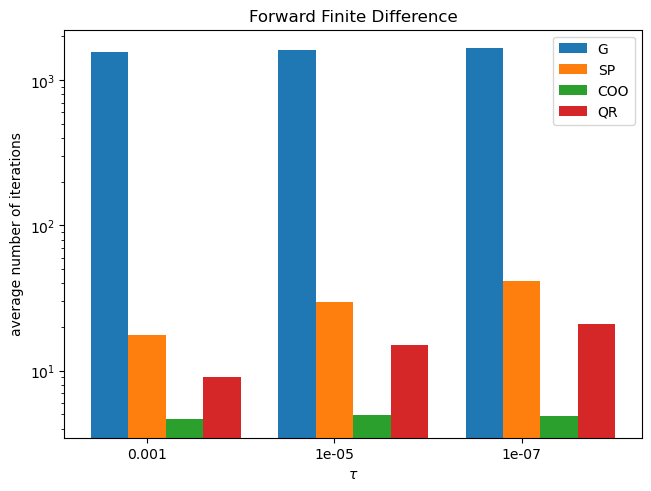

In [96]:
d = 10
l = 5

results = {}
ris = [[], [], []]

for fname in targets:
    for method in methods:
        for dtype in dir_types:
            r_name = f"{fname}_{method}_{dtype}_{d}_{l}"
            results[r_name] = []
            with open(f"{path}/{fname}_{d}/{opt_type}/{method}_{dtype}_{d}_{l}/{method}_{dtype}_{d}_{l}_{dtype}_{d}_{l}_{budget}.log", 'r') as f:
                lines = f.readlines()
                c = 0
                for line in lines:
                    spl = line.split(",")
                    ris[c].append(float(spl[1]))#(float(spl[1]), float(spl[2])))
                    c+=1


ris = np.asarray(ris).T

fig, ax  = plt.subplots(layout='constrained')
width = 0.20
x = np.arange(3)
taus = [0.001, 1e-5, 1e-7]
for i in range(ris.shape[0]):
    print(f"{dir_types[i]} => {ris[i, :]}")
gauss = ris[0, :]
for i in range(4):
#    if ris[i, :] != ris[i, :]:
#        continue
    r = ax.bar(x + width*i, ris[i, :], width, label=dir_types[i])
#    ax.bar_label(r, padding=3)

#ax.table(cellText=['A', 'B', 'C', 'D',
#                  rowLabels=rows,
#                      rowColours=colors,
#                      colLabels=columns,
#                      loc='bottom')
ax.set_yscale("log")
#ax.set_xticks([0, 1, 2], [0.001, 1e-5,1e-7])
ax.set_xlabel("$\\tau$")
ax.set_ylabel("average number of iterations")
ax.set_xticks(x + width, taus)
ax.set_title("Forward Finite Difference")
ax.legend()
#fig.tight_layout()


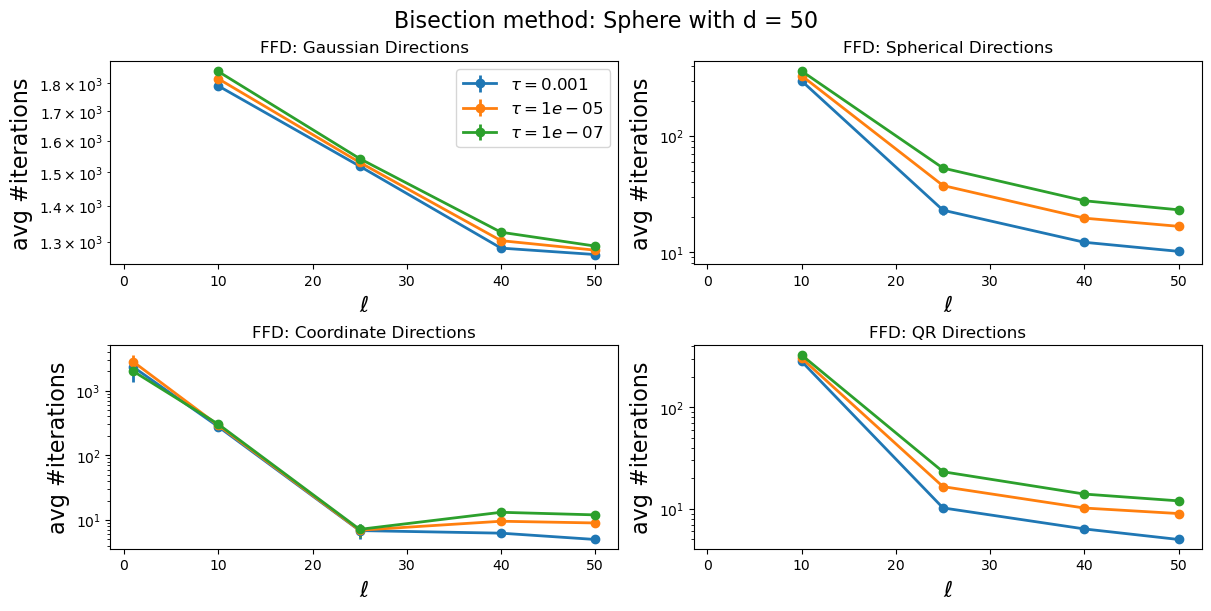

In [154]:
fname = "Sphere"
method = 'FFD'
out_ris = f"../results/convex_benchmark/img/{fname}/changing_l"
os.makedirs(out_ris, exist_ok=True)
dim_dirs = [
    (3, [1, 2, 3]),
    (5, [1, 3, 4, 5]),
    (10, [1, 3, 5, 7, 10]),
#    (15, [1, 5, 7, 10, 15]),
#    (18, [1, 5, 7, 10, 15, 18]),
    (20, [1, 5, 7, 10, 15, 20]),
    (50, [1, 10, 25, 40, 50]),
#    (100, [1, 30, 70, 100]),
#    (200, [1, 50, 150, 200])
]


#ls = [1, 3, 4, 5]#[1, 2, 3]#[1, 3, 5, 7, 10]
d, ls = dim_dirs[4]
results = {}
results_std = {}
# [G, SP, COO, QR]
ris = [[], [], [], []]
taus = [0.001, 1e-5, 1e-7]



for (i, dtype) in enumerate(dir_types):
    results[dtype] = {
        taus[0] : [],
        taus[1] : [],
        taus[2] : []
    }
    results_std[dtype] = {
        taus[0] : [],
        taus[1] : [],
        taus[2] : []
    }
    for l in ls:
        r_name = f"{fname}_{method}_{dtype}_{d}_{l}"
        with open(f"{path}/{fname}_{d}/{opt_type}/{method}_{dtype}_{d}_{l}/{method}_{dtype}_{d}_{l}_{budget}.log", 'r') as f:
            lines = f.readlines()
            c = 0
            for line in lines:
                spl = line.split(",")
                results[dtype][taus[c]].append((float(spl[1])))
                results_std[dtype][taus[c]].append((float(spl[2])))
                ris[i].append(float(spl[1]))#(float(spl[1]), float(spl[2])))
                c+=1


ris = np.asarray(ris).T

fig, axs  = plt.subplots(2, 2, figsize=(12, 6), layout='constrained')
for i in range(3):
    axs[0, 0].errorbar(ls, results['G'][taus[i]], yerr=results_std['G'][taus[i]], fmt='o-', lw=2, label="$\\tau = {}$".format(taus[i]))
    axs[0, 1].errorbar(ls, results['SP'][taus[i]], yerr=results_std['SP'][taus[i]], fmt='o-', lw=2, label="$\\tau = {}$".format(taus[i]))
    axs[1, 0].errorbar(ls, results['COO'][taus[i]], yerr=results_std['COO'][taus[i]], fmt='o-', lw=2, label="$\\tau = {}$".format(taus[i]))
    axs[1, 1].errorbar(ls, results['QR'][taus[i]], yerr=results_std['QR'][taus[i]], fmt='o-', lw=2, label="$\\tau = {}$".format(taus[i]))

axs[0, 0].set_title(f"{method}: Gaussian Directions")
axs[0, 1].set_title(f"{method}: Spherical Directions")
axs[1, 0].set_title(f"{method}: Coordinate Directions")
axs[1, 1].set_title(f"{method}: QR Directions")

    
for i in [0, 1]:
    for j in [0, 1]:
        axs[i, j].set_yscale("log")
        #ax.set_xticks([0, 1, 2], [0.001, 1e-5,1e-7])
        axs[i, j].set_xlabel("$\\ell$", fontsize=16)
        axs[i, j].set_ylabel("avg #iterations", fontsize=16)
        #ax.set_xticks(x + width, taus)
axs[0, 0].legend(fontsize=12)
fig.suptitle("Bisection method: Sphere with d = {}".format(d), fontsize=16)
#fig.tight_layout()
fig.savefig(f"{out_ris}/{fname}_{method}_{d}.pdf", bbox_inches='tight')
